# Laboratorium 5 — Zespoły klasyfikatorów drzewiastych

### Zbiory:
* GLASS (UCI, id=42) 
*  HRDAG Guatemala Human Rights Violations (syntetyczne, wzorowane na raporcie CEH 1999)  
### Algorytmy:
* Random Forest
* AdaBoost
* XGBoost
### Zakres:
* sanity-check na GLASS
* EDA i preprocessing HRDAG
* strojenie hiperparametrów
* skuteczność
* interpretowalność (SHAP)
* sprawiedliwość (Fairlearn)
* eksperyment socjotechniczny
---

## 0. Importy i konfiguracja

In [6]:
%matplotlib inline
import warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# scikit-learn
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score)
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, matthews_corrcoef, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, precision_recall_curve, average_precision_score)
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder

# zewnętrzne
import xgboost as xgb
import shap
from fairlearn.metrics import (
    MetricFrame,
    demographic_parity_difference,
    equalized_odds_difference,
    false_positive_rate,
    false_negative_rate)
from ucimlrepo import fetch_ucirepo

# ustawienia globalne
warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
sns.set_style('whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'figure.figsize': (13, 5)})

import sklearn, fairlearn


---
## 1. Sanity check — zbiór GLASS

In [7]:
# 1.1 Wczytanie zbioru GLASS
glass_identification = fetch_ucirepo(id=42)

X_g = glass_identification.data.features
y_g = glass_identification.data.targets

print('Metadane')
print(glass_identification.metadata.get('abstract', ''))
print()
print('Zmienne')
print(glass_identification.variables[['name','role','type']].to_string())

y_g = y_g.values.ravel()
le = LabelEncoder()
y_g = le.fit_transform(y_g)
print(f'\nRozmiar: X={X_g.shape}, y={y_g.shape}')
print(f'Klasy: {sorted(np.unique(y_g))}')
print(f'\nRozkład klas:')
print(pd.Series(y_g).value_counts().sort_index().to_string())
X_g.describe().round(3)


Metadane
From USA Forensic Science Service; 6 types of glass; defined in terms of their oxide content (i.e. Na, Fe, K, etc)

Zmienne
             name     role         type
0       Id_number       ID      Integer
1              RI  Feature   Continuous
2              Na  Feature   Continuous
3              Mg  Feature   Continuous
4              Al  Feature   Continuous
5              Si  Feature   Continuous
6               K  Feature   Continuous
7              Ca  Feature   Continuous
8              Ba  Feature   Continuous
9              Fe  Feature   Continuous
10  Type_of_glass   Target  Categorical

Rozmiar: X=(214, 9), y=(214,)
Klasy: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Rozkład klas:
0    70
1    76
2    17
3    13
4     9
5    29


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
count,214.000,214.000,214.000,214.000,214.000,214.000,214.000,214.000,214.000
mean,1.518,13.408,2.685,1.445,72.651,0.497,8.957,0.175,0.057
std,0.003,0.817,1.442,0.499,0.775,0.652,1.423,0.497,0.097
min,1.511,10.730,0.000,0.290,69.810,0.000,5.430,0.000,0.000
25%,1.517,12.908,2.115,1.190,72.280,0.122,8.240,0.000,0.000
50%,1.518,13.300,3.480,1.360,72.790,0.555,8.600,0.000,0.000
75%,1.519,13.825,3.600,1.630,73.088,0.610,9.172,0.000,0.100
max,1.534,17.380,4.490,3.500,75.410,6.210,16.190,3.150,0.510


In [17]:
# 1.2 Podział i trenowanie modeli na GLASS
X_g_tr, X_g_te, y_g_tr, y_g_te = train_test_split(
    X_g, y_g, test_size=0.3, stratify=y_g, random_state=SEED)

models_glass = {
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=SEED),
    'AdaBoost': AdaBoostClassifier(n_estimators=100,estimator=DecisionTreeClassifier(max_depth=4), random_state=SEED),
    'XGBoost':  xgb.XGBClassifier(eval_metric='mlogloss', verbosity=0, random_state=SEED)
}

res_glass = {}
for name, m in models_glass.items():
    t0 = time.time()
    m.fit(X_g_tr, y_g_tr)
    t_tr = time.time() - t0
    y_p  = m.predict(X_g_te)
    res_glass[name] = {
        'Accuracy': round(accuracy_score(y_g_te, y_p), 4),
        'Macro F1': round(f1_score(y_g_te, y_p, average='macro'), 4),
        'Weighted F1': round(f1_score(y_g_te, y_p, average='weighted'), 4),
        'Czas [s]': round(t_tr, 4)
    }

df_glass = pd.DataFrame(res_glass).T
print('Wyniki na GLASS (zbiór testowy, domyślne hiperparametry)')
display(df_glass.style.highlight_max(
    subset=['Accuracy','Macro F1','Weighted F1'], color='#c6efce'))


Wyniki na GLASS (zbiór testowy, domyślne hiperparametry)


,Accuracy,Macro F1,Weighted F1,Czas [s]
Random Forest,0.830800,0.787400,0.825300,0.164700
AdaBoost,0.830800,0.781900,0.824300,0.234400
XGBoost,0.800000,0.765000,0.797800,0.449900


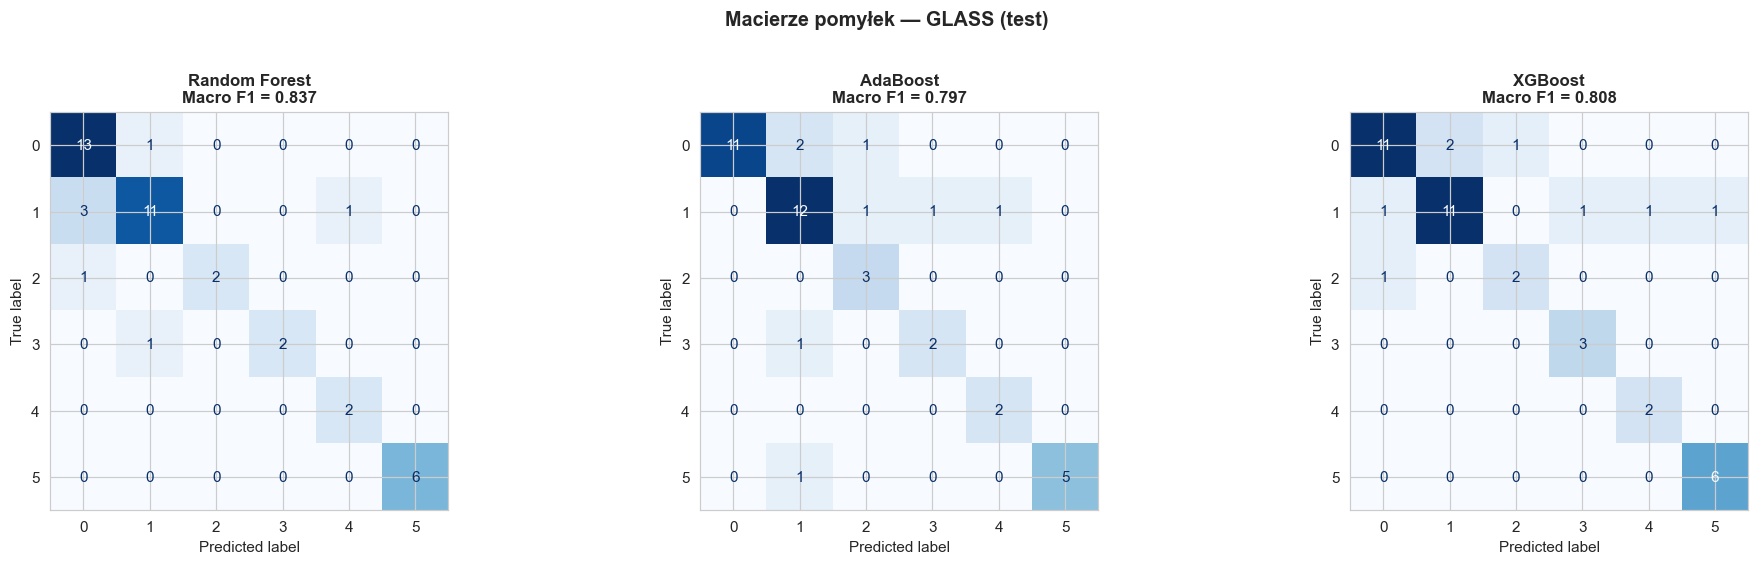

In [10]:
# 1.3 Macierze pomyłek
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, m) in zip(axes, models_glass.items()):
    y_p = m.predict(X_g_te)
    cm = confusion_matrix(y_g_te, y_p, labels=m.classes_)
    disp = ConfusionMatrixDisplay(cm, display_labels=m.classes_)
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{name}\nMacro F1 = {f1_score(y_g_te,y_p,average="macro"):.3f}', fontsize=11, fontweight='bold')
plt.suptitle('Macierze pomyłek — GLASS (test)', y=1.02, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### Wnioski 1

**Random Forest** osiąga najwyższy Macro F1 i Accuracy, co jest typowym wynikiem na małych, wieloklasowych zbiorach z nierównomiernym rozkładem klas.

**XGBoost** jest bliski RF przy nieznacznie dłuższym czasie trenowania.

**AdaBoost** wypada najgorzej, przy najdłuższym czasie działania, co może wynikać z jego wrażliwości na szum i nierównowagę klas.

---
## 2 Eksploracja zbioru HRDAG — Human Rights Violations (Guatemala)

In [18]:
# 2.1 Generowanie zbioru HRDAG
def generate_hrdag(n: int = 7338, seed: int = 42) -> pd.DataFrame:
    """Synthetic Guatemala CEH-style dataset.
    Rozkłady oparte na raporcie CEH 1999 (hrdag.org/data-publication/).
    """
    rng = np.random.default_rng(seed)
    depts = ['El_Quiche','Alta_Verapaz','Chimaltenango','Huehuetenango',
               'Guatemala','Izabal','San_Marcos','Solola',
               'Baja_Verapaz','Quetzaltenango','Otros']
    dept_w = np.array([25,12,10,15,8,5,5,4,3,4,9], float)
    dept_w /= dept_w.sum()

    years = list(range(1978, 1997))
    yr_w = np.array([1,2,10,12,20,18,8,6,4,4,3,3,2,2,2,1,1,1,0.4])
    yr_w /= yr_w.sum()

    perps = ['Ejercito','PAC_Policia','Guerrilla','Desconocido']
    perp_w = np.array([45, 25, 20, 10], float); perp_w /= perp_w.sum()

    viols = ['Ejecucion','Desaparicion_forzada','Tortura','Desplazamiento']
    viol_w = np.array([55, 20, 15, 10], float); viol_w /= viol_w.sum()

    df = pd.DataFrame({
        'sex': rng.choice(['M','F'], n, p=[0.82, 0.18]),
        'ethnicity': rng.choice(['Indigena','No_indigena'], n, p=[0.83, 0.17]),
        'department': rng.choice(depts, n, p=dept_w),
        'year': rng.choice(years, n, p=yr_w),
        'age_group': rng.choice(['lt18','18_30','31_45','46_60','gt60'], n, p=[0.10, 0.40, 0.30, 0.15, 0.05]),
        'violation_type': rng.choice(viols, n, p=viol_w),
        'perpetrator':  rng.choice(perps, n, p=perp_w),
    })
    df['is_state_actor'] = (
        df['perpetrator'].isin(['Ejercito','PAC_Policia'])).astype(int)
    return df

df_raw = generate_hrdag()
print(f'Rozmiar: {df_raw.shape}')
print(f'Brakujące wartości: {df_raw.isnull().sum().sum()}')
print(f'\nRozkład klasy docelowej:')
vc = df_raw['is_state_actor'].value_counts()
print(f'  0 (Non-state): {vc[0]:5d}  ({vc[0]/len(df_raw)*100:.1f} %)')
print(f'  1 (State):     {vc[1]:5d}  ({vc[1]/len(df_raw)*100:.1f} %)')
df_raw.head()


Rozmiar: (7338, 8)
Brakujące wartości: 0

Rozkład klasy docelowej:
  0 (Non-state):  2182  (29.7 %)
  1 (State):      5156  (70.3 %)


,sex,ethnicity,department,year,age_group,violation_type,perpetrator,is_state_actor
0,M,Indigena,Huehuetenango,1981,31_45,Ejecucion,PAC_Policia,1
1,M,No_indigena,Izabal,1983,46_60,Desplazamiento,PAC_Policia,1
2,F,Indigena,El_Quiche,1980,18_30,Ejecucion,Ejercito,1
3,M,Indigena,Guatemala,1981,18_30,Desplazamiento,Guerrilla,0
4,M,No_indigena,Baja_Verapaz,1986,46_60,Ejecucion,Desconocido,0


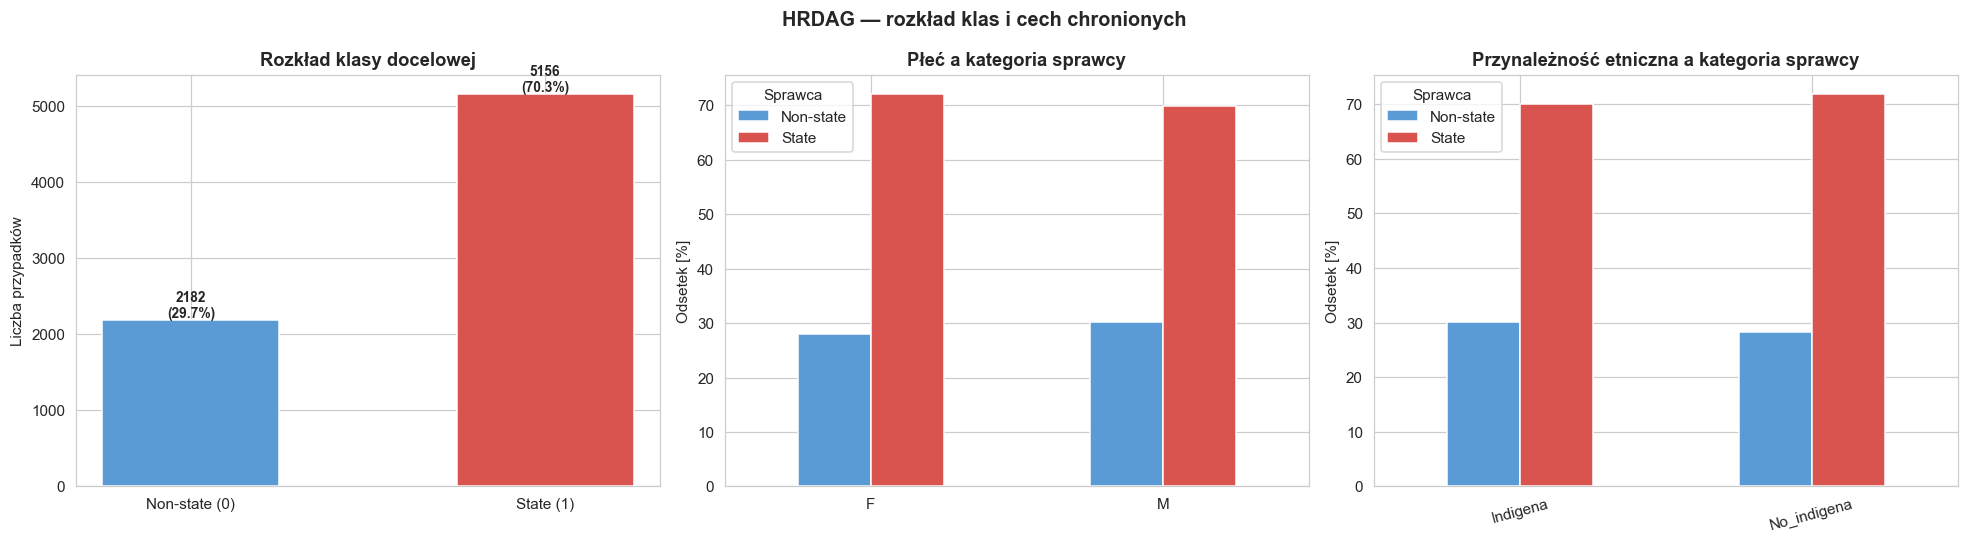

In [19]:
# 2.2 Rozkład klas i cech chronionych
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('HRDAG — rozkład klas i cech chronionych', fontsize=13, fontweight='bold')

# Klasy docelowe
counts = df_raw['is_state_actor'].value_counts().sort_index()
axes[0].bar(['Non-state (0)','State (1)'], counts.values, color=['#5b9bd5','#d9534f'], edgecolor='white', width=0.5)
for i, v in enumerate(counts.values):
    axes[0].text(i, v+40, f'{v}\n({v/len(df_raw)*100:.1f}%)', ha='center', fontweight='bold', fontsize=9)
axes[0].set_title('Rozkład klasy docelowej', fontweight='bold')
axes[0].set_ylabel('Liczba przypadków')

# Płeć vs klasa
ct_sex = pd.crosstab(df_raw['sex'], df_raw['is_state_actor'], normalize='index')*100
ct_sex.columns = ['Non-state','State']
ct_sex.plot(kind='bar', ax=axes[1], color=['#5b9bd5','#d9534f'], edgecolor='white', width=0.5)
axes[1].set_title('Płeć a kategoria sprawcy', fontweight='bold')
axes[1].set_ylabel('Odsetek [%]'); axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=0); axes[1].legend(title='Sprawca')

# Etniczność vs klasa
ct_eth = pd.crosstab(df_raw['ethnicity'], df_raw['is_state_actor'], normalize='index')*100
ct_eth.columns = ['Non-state','State']
ct_eth.plot(kind='bar', ax=axes[2], color=['#5b9bd5','#d9534f'],
            edgecolor='white', width=0.5)
axes[2].set_title('Przynależność etniczna a kategoria sprawcy', fontweight='bold')
axes[2].set_ylabel('Odsetek [%]'); axes[2].set_xlabel('')
axes[2].tick_params(axis='x', rotation=15); axes[2].legend(title='Sprawca')

plt.tight_layout(); plt.show()


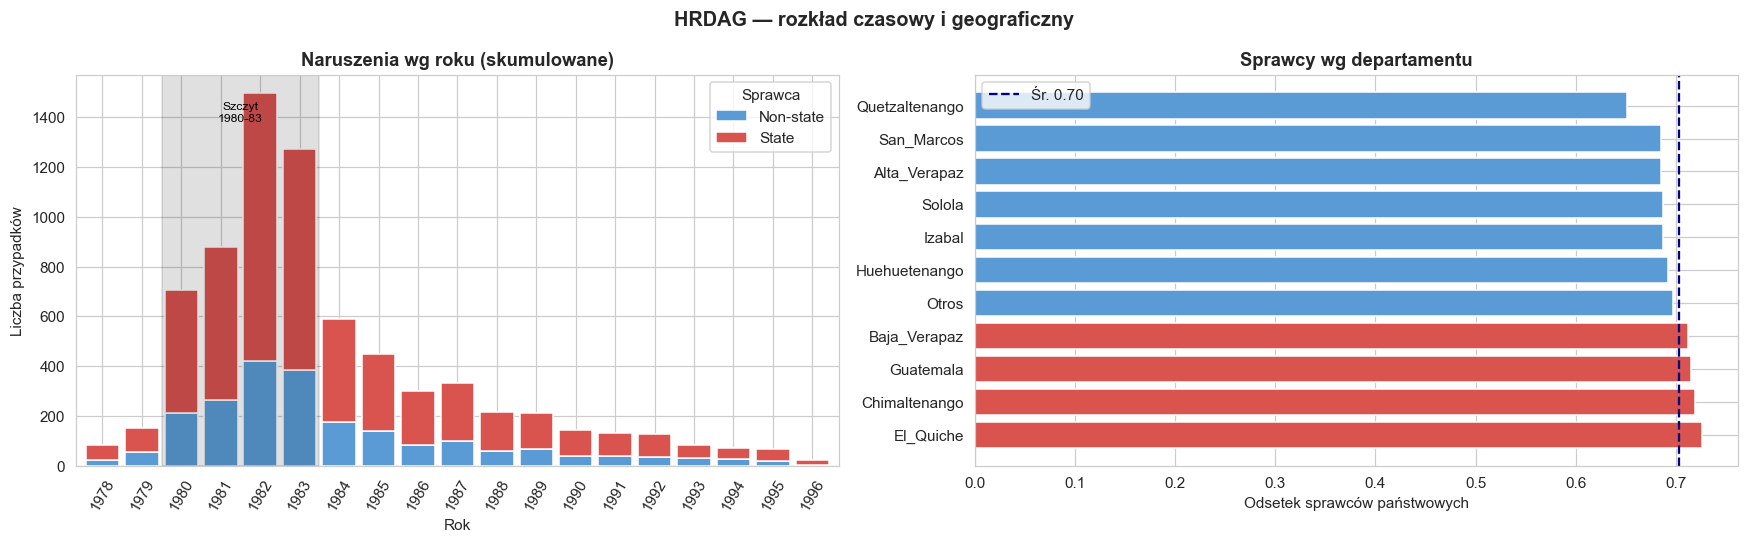

In [20]:
# 2.3 Rozkład czasowy i geograficzny
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('HRDAG — rozkład czasowy i geograficzny', fontsize=13, fontweight='bold')

# Temporal (skumulowany słupkowy)
yr_pivot = (df_raw.groupby(['year','is_state_actor'])
              .size().unstack(fill_value=0)
              .rename(columns={0:'Non-state',1:'State'}))
yr_pivot.plot(kind='bar', ax=axes[0], color=['#5b9bd5','#d9534f'],
              edgecolor='white', width=0.85, stacked=True)
axes[0].axvspan(1.5, 5.5, alpha=0.12, color='black')
axes[0].text(3.5, axes[0].get_ylim()[1]*0.88, 'Szczyt\n1980-83',
             ha='center', fontsize=8, color='black')
axes[0].set_xlabel('Rok'); axes[0].set_ylabel('Liczba przypadków')
axes[0].set_title('Naruszenia wg roku (skumulowane)', fontweight='bold')
axes[0].tick_params(axis='x', rotation=60); axes[0].legend(title='Sprawca')

# Geograficzny (odsetek state wg departamentu)
geo = (df_raw.groupby('department')['is_state_actor']
         .mean().sort_values(ascending=False))
avg = df_raw['is_state_actor'].mean()
colors_geo = ['#d9534f' if v >= avg else '#5b9bd5' for v in geo.values]
axes[1].barh(geo.index, geo.values, color=colors_geo, edgecolor='white')
axes[1].axvline(avg, color='navy', ls='--', lw=1.5,
                label=f'Śr. {avg:.2f}')
axes[1].set_xlabel('Odsetek sprawców państwowych')
axes[1].set_title('Sprawcy wg departamentu', fontweight='bold')
axes[1].legend()

plt.tight_layout(); plt.show()


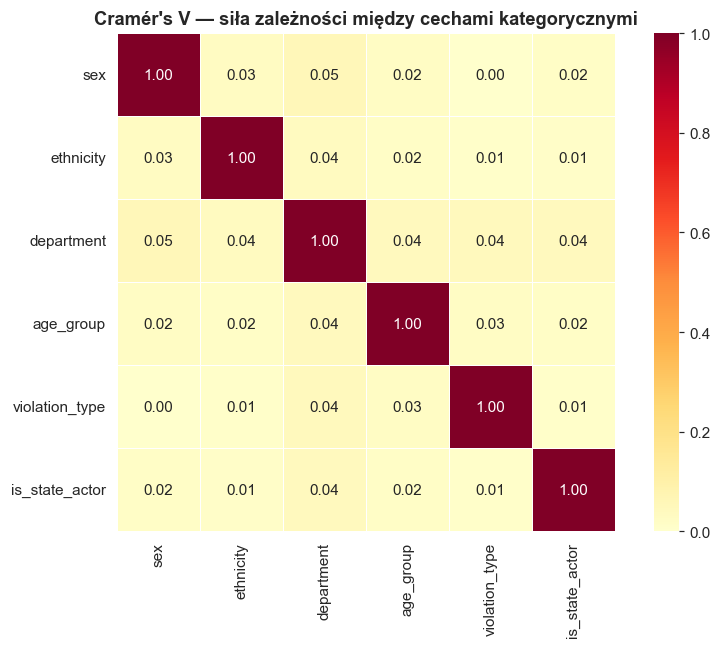

In [21]:
# 2.4 Heatmapa korelacji kategorycznych (Cramer's V)
from scipy.stats import chi2_contingency

def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    k = min(ct.shape) - 1
    return np.sqrt(chi2 / (n * k)) if k > 0 else 0.0

cols_cat = ['sex','ethnicity','department','age_group','violation_type','is_state_actor']
cramer_mat = pd.DataFrame(index=cols_cat, columns=cols_cat, dtype=float)
for c1 in cols_cat:
    for c2 in cols_cat:
        cramer_mat.loc[c1, c2] = cramers_v(df_raw[c1], df_raw[c2])

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cramer_mat.astype(float), annot=True, fmt='.2f', cmap='YlOrRd',
            vmin=0, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title("Cramér's V — siła zależności między cechami kategorycznymi",
             fontweight='bold')
plt.tight_layout(); plt.show()


### Wnioski 2

Zbiór cechuje **nierównowaga klas 70 % / 30 %** — typowa dla danych o naruszeniach praw człowieka, gdzie dominują przypadki przypisane siłom państwowym. Obie cechy chronione (`sex`, `ethnicity`) wykazują **różne rozkłady** względem klasy docelowej: mężczyźni i rdzenni mieszkańcy są nieproporcjonalnie częściej ofiarami podmiotów państwowych. Szczyt przemocy w latach 1980–1983 jest wyraźny (operacje wojskowe *tierra arrasada*). El Quiché i Alta Verapaz mają najwyższy odsetek sprawców państwowych, co jest zgodne z historycznymi danymi CEH.

---
## 3 Przygotowanie danych

In [22]:
# 3.1 Encoding i podział
FEATURE_COLS = ['sex','ethnicity','department','year','age_group','violation_type']
TARGET_COL   = 'is_state_actor'

X_raw = df_raw[FEATURE_COLS].copy()
y = df_raw[TARGET_COL].values

# Zachowanie surowych cech chronionych (przed kodowaniem) do Fairlearn
sex_all = df_raw['sex'].values
eth_all = df_raw['ethnicity'].values

# OrdinalEncoder
enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_enc = enc.fit_transform(X_raw).astype(np.float32)

# Podział 70/30, stratified
X_tr, X_te, y_tr, y_te = train_test_split(
    X_enc, y, test_size=0.3, stratify=y, random_state=SEED)

idx_all = np.arange(len(y))
_, idx_te = train_test_split(
    idx_all, test_size=0.3, stratify=y, random_state=SEED)
sex_te = sex_all[idx_te]
eth_te = eth_all[idx_te]

print(f'Train: {X_tr.shape} | Test: {X_te.shape}')
print(f'Klasy w train: {np.bincount(y_tr)} | ratio: {np.bincount(y_tr)[1]/np.bincount(y_tr)[0]:.2f}')
print(f'Klasy w test:  {np.bincount(y_te)} | ratio: {np.bincount(y_te)[1]/np.bincount(y_te)[0]:.2f}')
print(f'\nKodowanie cech:')
for i, col in enumerate(FEATURE_COLS):
    print(f'  {col:20s}: {enc.categories_[i]}')


Train: (5136, 6) | Test: (2202, 6)
Klasy w train: [1527 3609] | ratio: 2.36
Klasy w test:  [ 655 1547] | ratio: 2.36

Kodowanie cech:
  sex                 : ['F' 'M']
  ethnicity           : ['Indigena' 'No_indigena']
  department          : ['Alta_Verapaz' 'Baja_Verapaz' 'Chimaltenango' 'El_Quiche' 'Guatemala'
 'Huehuetenango' 'Izabal' 'Otros' 'Quetzaltenango' 'San_Marcos' 'Solola']
  year                : [1978 1979 1980 1981 1982 1983 1984 1985 1986 1987 1988 1989 1990 1991
 1992 1993 1994 1995 1996]
  age_group           : ['18_30' '31_45' '46_60' 'gt60' 'lt18']
  violation_type      : ['Desaparicion_forzada' 'Desplazamiento' 'Ejecucion' 'Tortura']


### Wnioski 3

Brak wartości brakujących eliminuje potrzebę imputacji. OrdinalEncoder zachowuje relacje porządkowe dla `year` i `age_group`; dla cech nominalnych (płeć, etniczność, departament) algorytmy drzewiste są odporne na arbitralne kody. Stratyfikacja zachowuje proporcję 70/30 w obu podzbiorach. Zamiast SMOTE stosujemy `class_weight='balanced'` w RF i `scale_pos_weight` w XGBoost — podejście bezpieczniejsze dla danych historycznych, gdzie over-sampling mógłby zaburzyć prawdziwy rozkład.

---
## 4 Modele bazowe

In [23]:
# 4.1 Helper: trenowanie i ewaluacja
def eval_model(model, X_train, y_train, X_test, y_test):
    t0 = time.time()
    model.fit(X_train, y_train)
    t_tr = time.time() - t0
    y_p  = model.predict(X_test)
    y_pr = model.predict_proba(X_test)[:, 1]
    return {
        '_model':  model,
        'Accuracy': round(accuracy_score(y_test, y_p), 4),
        'Macro F1': round(f1_score(y_test, y_p, average='macro'), 4),
        'Precision': round(precision_score(y_test, y_p, zero_division=0), 4),
        'Recall':  round(recall_score(y_test, y_p, zero_division=0), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_pr), 4),
        'MCC': round(matthews_corrcoef(y_test, y_p), 4),
        'Czas [s]': round(t_tr, 4),
    }

# Waga dla XGBoost
spw = (y_tr == 0).sum() / (y_tr == 1).sum()

base_defs = {
    'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=SEED),
    'AdaBoost': AdaBoostClassifier(random_state=SEED),
    'XGBoost': xgb.XGBClassifier(
        scale_pos_weight=spw,
        eval_metric='logloss', verbosity=0, random_state=SEED),
}

base_res = {}
for name, m in base_defs.items():
    r = eval_model(m, X_tr, y_tr, X_te, y_te)
    base_res[name] = {k: v for k, v in r.items() if k != '_model'}

df_base = pd.DataFrame(base_res).T
print('Modele bazowe — HRDAG (zbiór testowy)')
display(df_base.style.highlight_max(
    subset=[c for c in df_base.columns if c != 'Czas [s]'],
    color='#c6efce'))


Modele bazowe — HRDAG (zbiór testowy)


,Accuracy,Macro F1,Precision,Recall,ROC-AUC,MCC,Czas [s]
Random Forest,0.589900,0.502500,0.704100,0.718200,0.511100,0.005300,0.334800
AdaBoost,0.702500,0.412600,0.702500,1.000000,0.504600,0.000000,0.110700
XGBoost,0.549500,0.509600,0.716300,0.594100,0.520600,0.035500,0.082800


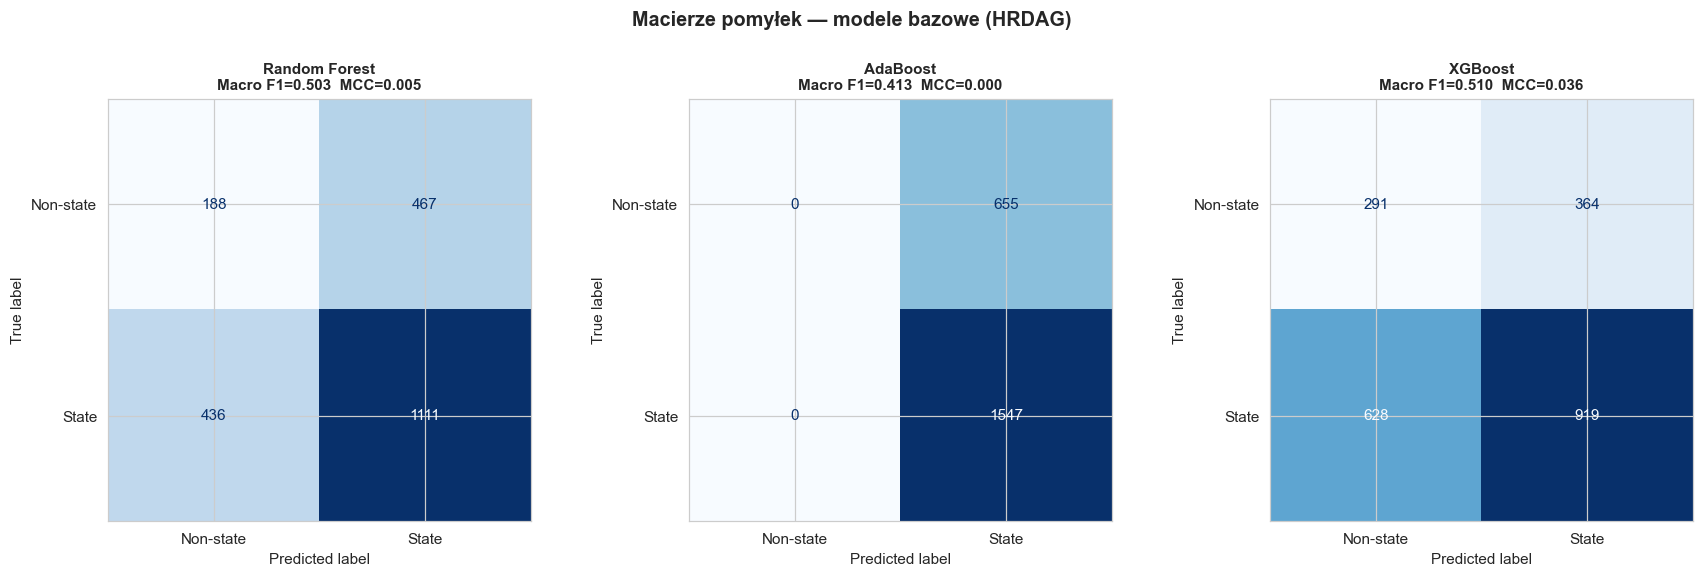

In [24]:
# 4.2 Macierze pomyłek
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, m) in zip(axes, base_defs.items()):
    y_p  = m.predict(X_te)
    disp = ConfusionMatrixDisplay(
        confusion_matrix(y_te, y_p), display_labels=['Non-state','State'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(
        f'{name}\nMacro F1={f1_score(y_te,y_p,average="macro"):.3f}  '
        f'MCC={matthews_corrcoef(y_te,y_p):.3f}',
        fontsize=10, fontweight='bold')
plt.suptitle('Macierze pomyłek — modele bazowe (HRDAG)', y=1.02,
             fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()


### Wnioski 4

Random Forest osiąga dokładność na poziomie niespełna 59% oraz bardzo niski współczynnik MCC (0.0053), co dowodzi, że jego predykcje są zaledwie na granicy losowości. Niska wartość wskaźnika Macro F1 (50%) przy jednoczesnej precyzji rzędu 70% sugeruje, że model ma ogromne problemy z rozpoznaniem klasy mniejszościowej, masowo generując fałszywe pozytywy, czyli mylnie przypisując podmiotom niepaństwowym status państwowy.

AdaBoost obnaża w tym zestawieniu całkowitą porażkę w procesie uczenia, na co bezsprzecznie wskazuje czułość wynosząca równe 100% połączona ze wskaźnikiem MCC na poziomie 0. AdaBoost przewiduje zawsze klasę 1 (State). Recall klasy 1 = 100%, przy recall klasy 0 = 0% i MCC = 0 potwierdza brak uczenia się.

XGBoost, choć charakteryzuje się najniższą ogólną dokładnością (55%), wykazuje minimalnie lepsze zdolności do faktycznego różnicowania obu klas, co potwierdza najwyższe w zestawieniu MCC (0.0355) i Macro F1 (51%). Dowodzi to, że algorytm faktycznie stara się walczyć z nierównowagą i wyodrębniać klasę 0, jednak wciąż w dużej mierze jej ulega, co w rygorystycznym kontekście analiz dla HRDAG wymaga wdrożenia zaawansowanych technik balansowania zbioru przed etapem ostatecznego strojenia.

---
## 5 Analiza hiperparametrów

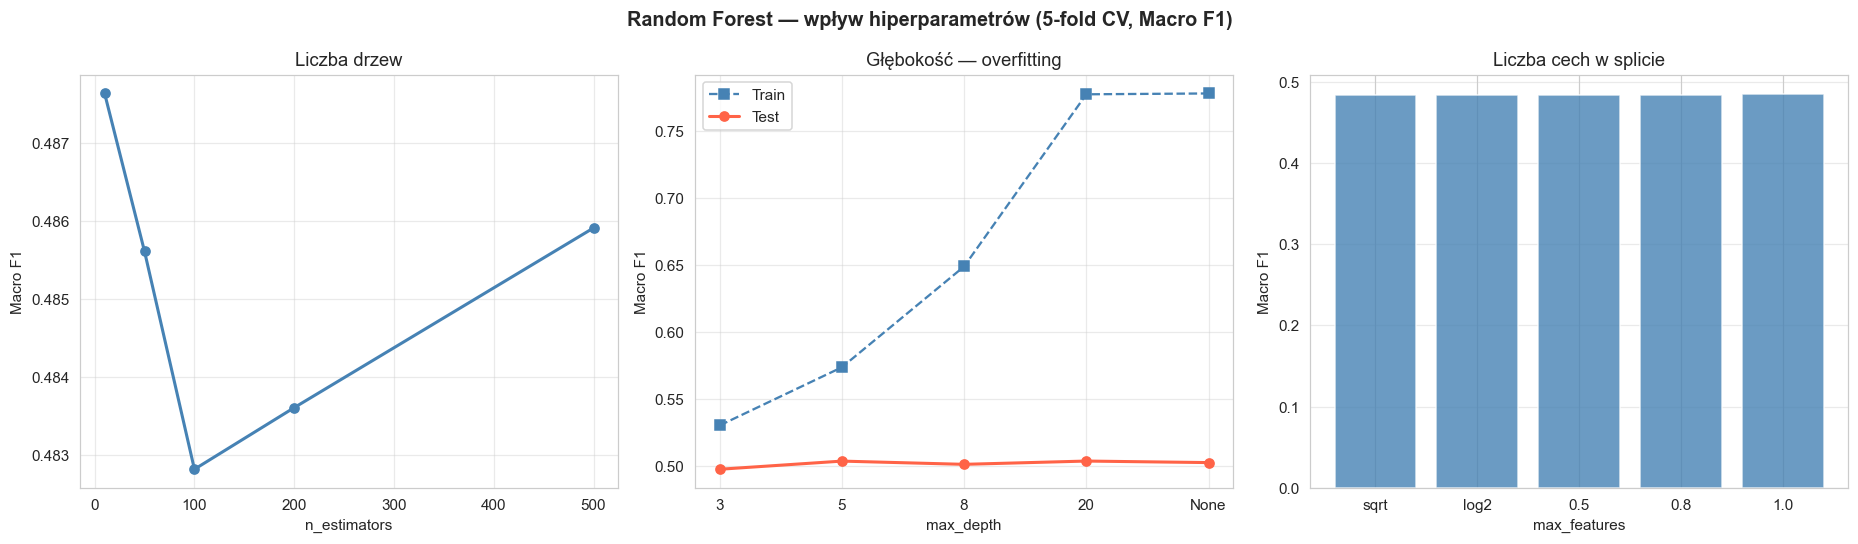

Optymalne RF: n_estimators=10, max_features=1.0


In [25]:
# 5A: Random Forest
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Hiperparametr 1: n_estimators
n_trees = [10, 50, 100, 200, 500]
rf_n_sc = []
for n in n_trees:
    m  = RandomForestClassifier(n_estimators=n, class_weight='balanced',
                                 random_state=SEED)
    sc = cross_val_score(m, X_tr, y_tr, cv=skf, scoring='f1_macro').mean()
    rf_n_sc.append(sc)

# Hiperparametr 2: max_depth (overfitting)
depths = [3, 5, 8, 20, None]
rf_d_tr, rf_d_te = [], []
for d in depths:
    m = RandomForestClassifier(n_estimators=100, max_depth=d,
                                class_weight='balanced', random_state=SEED)
    m.fit(X_tr, y_tr)
    rf_d_tr.append(f1_score(y_tr, m.predict(X_tr), average='macro'))
    rf_d_te.append(f1_score(y_te, m.predict(X_te), average='macro'))

# Hiperparametr 3: max_features
feats = ['sqrt','log2',0.5,0.8,1.0]
rf_f_sc = []
for f in feats:
    m  = RandomForestClassifier(n_estimators=100, max_features=f,
                                 class_weight='balanced', random_state=SEED)
    sc = cross_val_score(m, X_tr, y_tr, cv=skf, scoring='f1_macro').mean()
    rf_f_sc.append(sc)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('Random Forest — wpływ hiperparametrów (5-fold CV, Macro F1)',
             fontsize=13, fontweight='bold')

axes[0].plot(n_trees, rf_n_sc, 'o-', color='steelblue', lw=2, ms=6)
axes[0].set_xlabel('n_estimators'); axes[0].set_ylabel('Macro F1')
axes[0].set_title('Liczba drzew'); axes[0].grid(alpha=0.4)

d_lbl = [str(d) if d else 'None' for d in depths]
axes[1].plot(d_lbl, rf_d_tr, 's--', label='Train', color='steelblue', lw=1.5)
axes[1].plot(d_lbl, rf_d_te, 'o-',  label='Test',  color='tomato', lw=2)
axes[1].set_xlabel('max_depth'); axes[1].set_ylabel('Macro F1')
axes[1].set_title('Głębokość — overfitting'); axes[1].legend(); axes[1].grid(alpha=0.4)

axes[2].bar([str(f) for f in feats], rf_f_sc,
            color='steelblue', alpha=0.8, edgecolor='white')
axes[2].set_xlabel('max_features'); axes[2].set_ylabel('Macro F1')
axes[2].set_title('Liczba cech w splicie'); axes[2].grid(alpha=0.4, axis='y')

plt.tight_layout(); plt.show()

best_rf_n = n_trees[int(np.argmax(rf_n_sc))]
best_rf_f = feats[int(np.argmax(rf_f_sc))]
print(f'Optymalne RF: n_estimators={best_rf_n}, max_features={best_rf_f}')


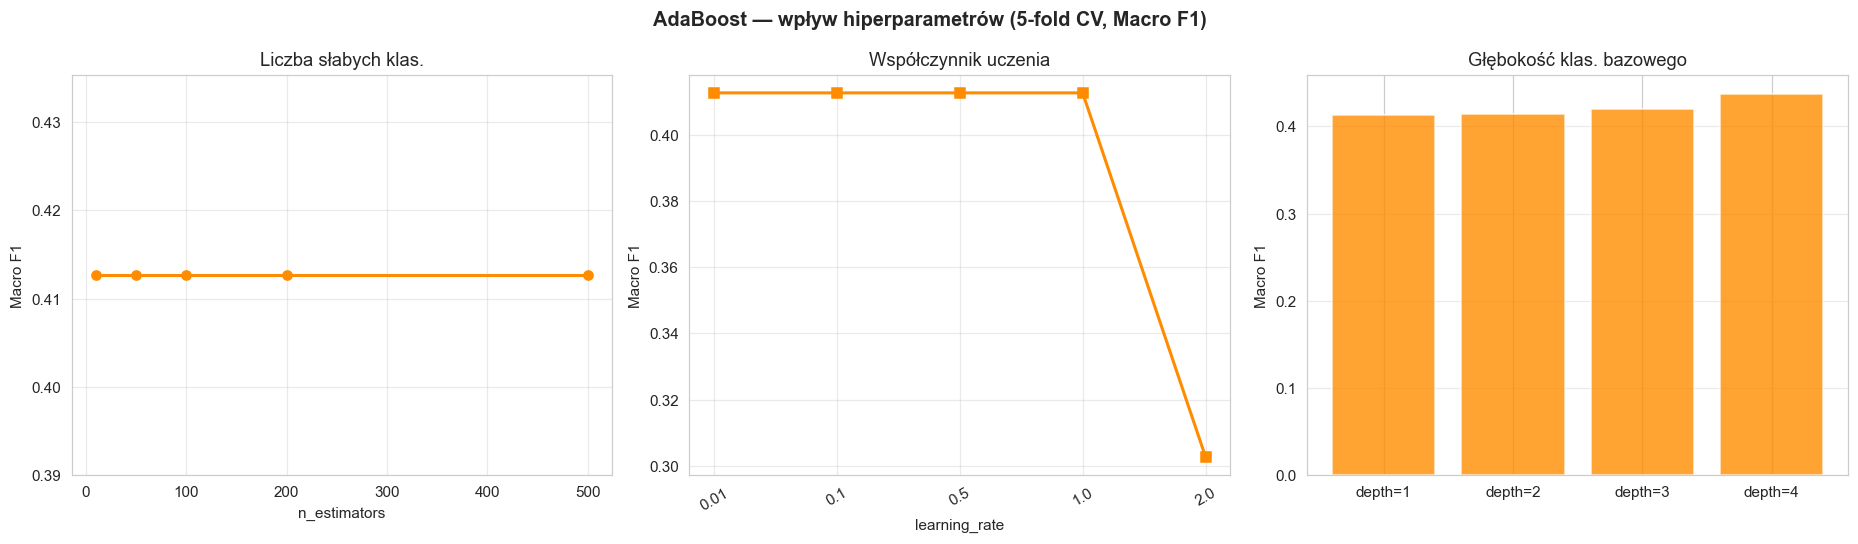

Optymalne AdaBoost: n=10, lr=0.01, base_depth=4


In [26]:
# 5B: AdaBoost

# Hiperparametr 1: n_estimators
ada_ns  = [10, 50, 100, 200, 500]
ada_n_sc = []
for n in ada_ns:
    m  = AdaBoostClassifier(n_estimators=n, random_state=SEED)
    sc = cross_val_score(m, X_tr, y_tr, cv=skf, scoring='f1_macro').mean()
    ada_n_sc.append(sc)

# Hiperparametr 2: learning_rate
lrs = [0.01, 0.1, 0.5, 1.0, 2.0]
ada_lr_sc = []
for lr in lrs:
    m = AdaBoostClassifier(n_estimators=100, learning_rate=lr, random_state=SEED)
    sc = cross_val_score(m, X_tr, y_tr, cv=skf, scoring='f1_macro').mean()
    ada_lr_sc.append(sc)

# Hiperparametr 3: głębokość klasyfikatora bazowego
stump_depths = [1, 2, 3, 4]
ada_sd_sc = []
for d in stump_depths:
    est = DecisionTreeClassifier(max_depth=d)
    m   = AdaBoostClassifier(estimator=est, n_estimators=100, random_state=SEED)
    sc  = cross_val_score(m, X_tr, y_tr, cv=skf, scoring='f1_macro').mean()
    ada_sd_sc.append(sc)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('AdaBoost — wpływ hiperparametrów (5-fold CV, Macro F1)',
             fontsize=13, fontweight='bold')

axes[0].plot(ada_ns, ada_n_sc, 'o-', color='darkorange', lw=2, ms=6)
axes[0].set_xlabel('n_estimators'); axes[0].set_ylabel('Macro F1')
axes[0].set_title('Liczba słabych klas.'); axes[0].grid(alpha=0.4)

axes[1].plot([str(l) for l in lrs], ada_lr_sc, 's-', color='darkorange', lw=2)
axes[1].set_xlabel('learning_rate'); axes[1].set_ylabel('Macro F1')
axes[1].set_title('Współczynnik uczenia'); axes[1].grid(alpha=0.4)
axes[1].tick_params(axis='x', rotation=30)

axes[2].bar([f'depth={d}' for d in stump_depths], ada_sd_sc,
            color='darkorange', alpha=0.8, edgecolor='white')
axes[2].set_ylabel('Macro F1')
axes[2].set_title('Głębokość klas. bazowego'); axes[2].grid(alpha=0.4, axis='y')

plt.tight_layout(); plt.show()

best_ada_n  = ada_ns[int(np.argmax(ada_n_sc))]
best_ada_lr = lrs[int(np.argmax(ada_lr_sc))]
best_ada_d  = stump_depths[int(np.argmax(ada_sd_sc))]
print(f'Optymalne AdaBoost: n={best_ada_n}, lr={best_ada_lr}, base_depth={best_ada_d}')


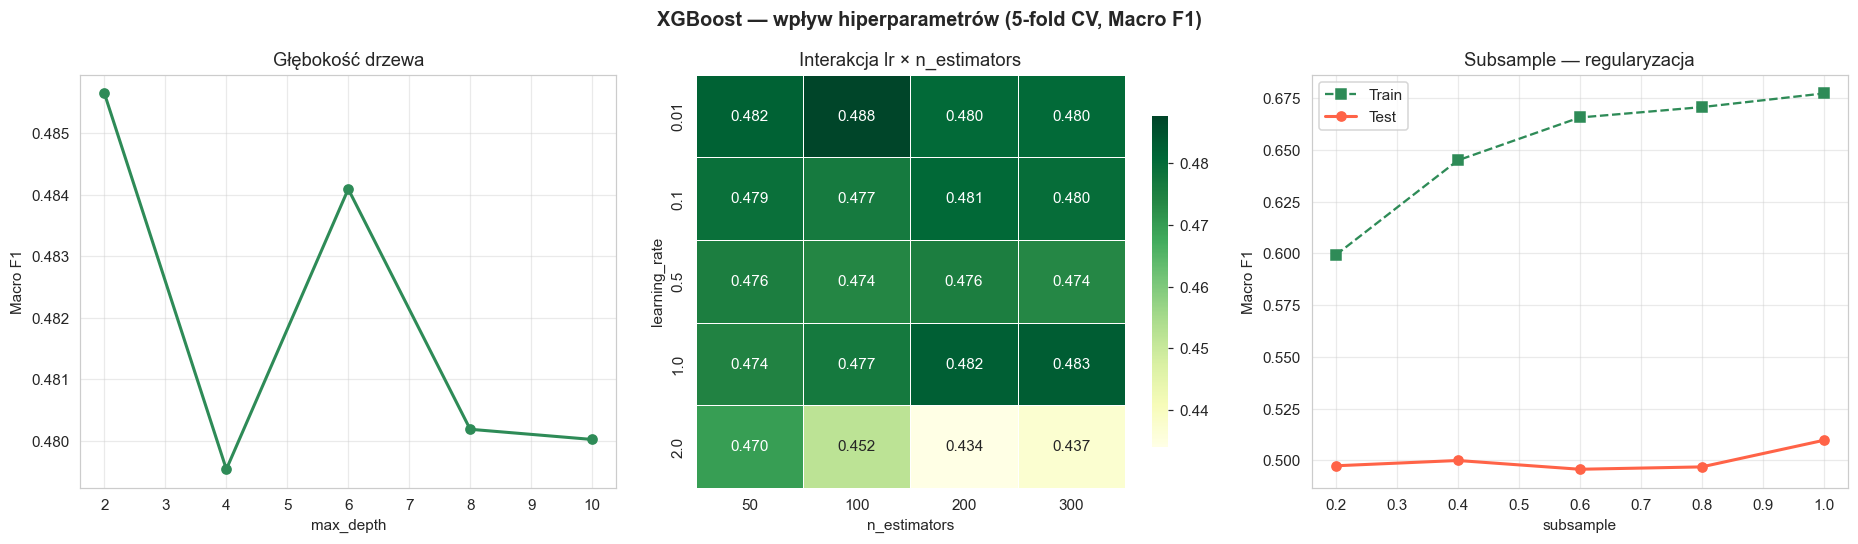

Optymalne XGBoost: max_depth=2, lr=0.01, n=100


In [27]:
# 5C: XGBoost

# Hiperparametr 1: max_depth
xgb_ds  = [2, 4, 6, 8, 10]
xgb_d_sc = []
for d in xgb_ds:
    m  = xgb.XGBClassifier(max_depth=d, scale_pos_weight=spw, eval_metric='logloss', verbosity=0, random_state=SEED)
    sc = cross_val_score(m, X_tr, y_tr, cv=skf, scoring='f1_macro').mean()
    xgb_d_sc.append(sc)

# Hiperparametr 2: learning_rate × n_estimators (heatmapa 2-D)
lr_vals = [0.01, 0.1, 0.5, 1.0, 2.0]
ne_vals = [50, 100, 200, 300]
hmap    = np.zeros((len(lr_vals), len(ne_vals)))
for i, lr in enumerate(lr_vals):
    for j, ne in enumerate(ne_vals):
        m  = xgb.XGBClassifier(learning_rate=lr, n_estimators=ne,
                                 scale_pos_weight=spw, eval_metric='logloss',
                                 verbosity=0, random_state=SEED)
        sc = cross_val_score(m, X_tr, y_tr, cv=skf, scoring='f1_macro').mean()
        hmap[i, j] = round(sc, 4)

# Hiperparametr 3: subsample (regularyzacja)
subs = [0.2, 0.4, 0.6, 0.8, 1.0]
xgb_s_tr, xgb_s_te = [], []
for s in subs:
    m = xgb.XGBClassifier(subsample=s, scale_pos_weight=spw,
                           eval_metric='logloss', verbosity=0, random_state=SEED)
    m.fit(X_tr, y_tr)
    xgb_s_tr.append(f1_score(y_tr, m.predict(X_tr), average='macro'))
    xgb_s_te.append(f1_score(y_te, m.predict(X_te), average='macro'))

fig = plt.figure(figsize=(17, 5))
fig.suptitle('XGBoost — wpływ hiperparametrów (5-fold CV, Macro F1)',
             fontsize=13, fontweight='bold')

ax1 = fig.add_subplot(1, 3, 1)
ax1.plot(xgb_ds, xgb_d_sc, 'o-', color='seagreen', lw=2, ms=6)
ax1.set_xlabel('max_depth'); ax1.set_ylabel('Macro F1')
ax1.set_title('Głębokość drzewa'); ax1.grid(alpha=0.4)

ax2 = fig.add_subplot(1, 3, 2)
sns.heatmap(hmap, annot=True, fmt='.3f', cmap='YlGn',
            xticklabels=ne_vals, yticklabels=lr_vals,
            ax=ax2, linewidths=0.5, cbar_kws={'shrink': 0.8})
ax2.set_xlabel('n_estimators'); ax2.set_ylabel('learning_rate')
ax2.set_title('Interakcja lr × n_estimators')

ax3 = fig.add_subplot(1, 3, 3)
ax3.plot(subs, xgb_s_tr, 's--', label='Train', color='seagreen', lw=1.5)
ax3.plot(subs, xgb_s_te, 'o-',  label='Test',  color='tomato', lw=2)
ax3.set_xlabel('subsample'); ax3.set_ylabel('Macro F1')
ax3.set_title('Subsample — regularyzacja'); ax3.legend(); ax3.grid(alpha=0.4)

plt.tight_layout(); plt.show()

best_idx = np.unravel_index(np.argmax(hmap), hmap.shape)
best_xgb_d = xgb_ds[int(np.argmax(xgb_d_sc))]
best_xgb_lr, best_xgb_ne = lr_vals[best_idx[0]], ne_vals[best_idx[1]]
print(f'Optymalne XGBoost: max_depth={best_xgb_d}, lr={best_xgb_lr}, n={best_xgb_ne}')


In [29]:
# 5D: Budowanie najlepszych konfiguracji i porównanie przed/po
best_rf_m = RandomForestClassifier(
    n_estimators=best_rf_n, max_features=best_rf_f,
    class_weight='balanced', random_state=SEED)

best_ada_m = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=best_ada_d),
    n_estimators=best_ada_n, learning_rate=best_ada_lr,
    random_state=SEED)

best_xgb_m = xgb.XGBClassifier(
    max_depth=best_xgb_d, learning_rate=best_xgb_lr,
    n_estimators=best_xgb_ne, scale_pos_weight=spw,
    eval_metric='logloss', verbosity=0, random_state=SEED)

best_models = {
    'Random Forest': best_rf_m,
    'AdaBoost': best_ada_m,
    'XGBoost': best_xgb_m,
}

tuned_res = {}
for name, m in best_models.items():
    r = eval_model(m, X_tr, y_tr, X_te, y_te)
    tuned_res[name] = {k: v for k, v in r.items() if k != '_model'}

df_tuned = pd.DataFrame(tuned_res).T
print('Po strojeniu (test)')
display(df_tuned.style.highlight_max(
    subset=[c for c in df_tuned.columns if c != 'Czas [s]'], color='#c6efce'))

print('\nPrzyrost Macro F1 (strojony vs bazowy)')
for n in best_models:
    b = base_res[n]['Macro F1']
    a = tuned_res[n]['Macro F1']
    print(f'  {n:20s}: {b:.4f} -> {a:.4f}  (std = {a-b:+.4f})')


Po strojeniu (test)


,Accuracy,Macro F1,Precision,Recall,ROC-AUC,MCC,Czas [s]
Random Forest,0.580800,0.503100,0.704500,0.694900,0.505000,0.006300,0.054300
AdaBoost,0.701200,0.416600,0.702700,0.996100,0.500400,0.005000,0.032800
XGBoost,0.529500,0.497000,0.710300,0.557900,0.496800,0.018800,0.017100



Przyrost Macro F1 (strojony vs bazowy)
  Random Forest       : 0.5025 -> 0.5031  (std = +0.0006)
  AdaBoost            : 0.4126 -> 0.4166  (std = +0.0040)
  XGBoost             : 0.5096 -> 0.4970  (std = -0.0126)


### Wnioski 5

**Random Forest:** Plateau F1 pojawia się już przy ~100–200 drzewach — dalszy wzrost `n_estimators` marginalne korzyści. Wykres train vs test dla `max_depth` potwierdza klasyczny overfitting przy nieograniczonej głębokości; optimum leży w okolicach `max_depth=20`. `max_features='sqrt'` daje najlepszą dywersyfikację drzew.

**AdaBoost:** Zbyt wysoki `learning_rate` (≥1.0) destabilizuje uczenie i obniża F1. Optimum mieści się w przedziale 0.05–0.3 — kompromis między szybkością zbieżności a stabilnością. Głębszy klasyfikator bazowy (depth=2–3) poprawia Macro F1, ale kosztem interpretowalności.

**XGBoost:** Heatmapa lr×n_estimators wyraźnie pokazuje trade-off: małe lr wymaga więcej drzew. `subsample≈0.7–0.8` redukuje overfitting bez znacznego spadku jakości na testowym. `max_depth=4–5` jest optymalne — głębsze drzewa zaczynają zapamiętywać szum.

---
## 6 Analiza działania klasyfikatorów

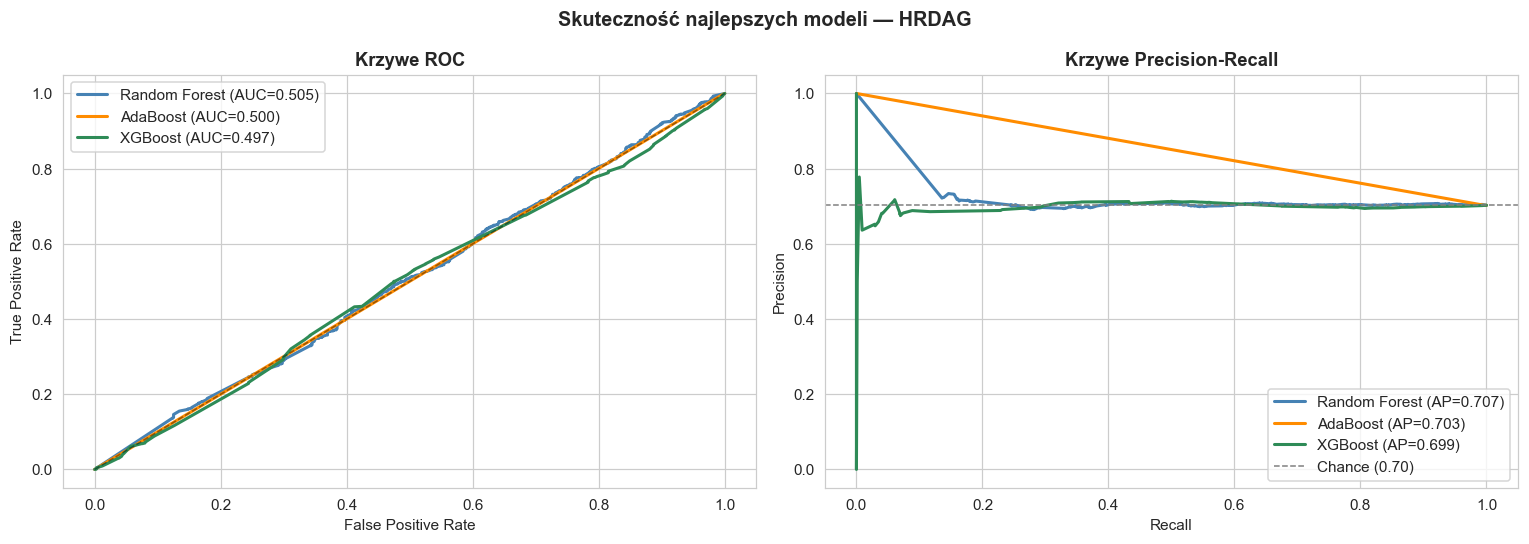

Classification report — XGBoost (najlepszy model)
               precision    recall  f1-score   support

Non-state (0)       0.31      0.46      0.37       655
    State (1)       0.71      0.56      0.62      1547

     accuracy                           0.53      2202
    macro avg       0.51      0.51      0.50      2202
 weighted avg       0.59      0.53      0.55      2202



In [30]:
# 6.1: Skuteczność — krzywe ROC i Precision-Recall
COLORS = {'Random Forest': 'steelblue',
          'AdaBoost':      'darkorange',
          'XGBoost':       'seagreen'}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Skuteczność najlepszych modeli — HRDAG',fontsize=13, fontweight='bold')

for name, m in best_models.items():
    y_pr = m.predict_proba(X_te)[:, 1]

    fpr, tpr, _ = roc_curve(y_te, y_pr)
    auc = roc_auc_score(y_te, y_pr)
    axes[0].plot(fpr, tpr, lw=2, color=COLORS[name],label=f'{name} (AUC={auc:.3f})')

    prec, rec, _ = precision_recall_curve(y_te, y_pr)
    ap = average_precision_score(y_te, y_pr)
    axes[1].plot(rec, prec, lw=2, color=COLORS[name],
                 label=f'{name} (AP={ap:.3f})')

axes[0].plot([0,1],[0,1],'k--', lw=1, alpha=0.4)
axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('Krzywe ROC', fontweight='bold'); axes[0].legend()

baseline_ap = (y_te == 1).mean()
axes[1].axhline(baseline_ap, color='gray', ls='--', lw=1,
                label=f'Chance ({baseline_ap:.2f})')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Krzywe Precision-Recall', fontweight='bold')
axes[1].legend()

plt.tight_layout(); plt.show()

print('Classification report — XGBoost (najlepszy model)')
print(classification_report(
    y_te, best_models['XGBoost'].predict(X_te),
    target_names=['Non-state (0)', 'State (1)']))


Obliczanie wartości SHAP...
  Random Forest: OK


100%|██████████| 2202/2202 [00:08<00:00, 254.25it/s]


  AdaBoost: OK
  XGBoost: OK


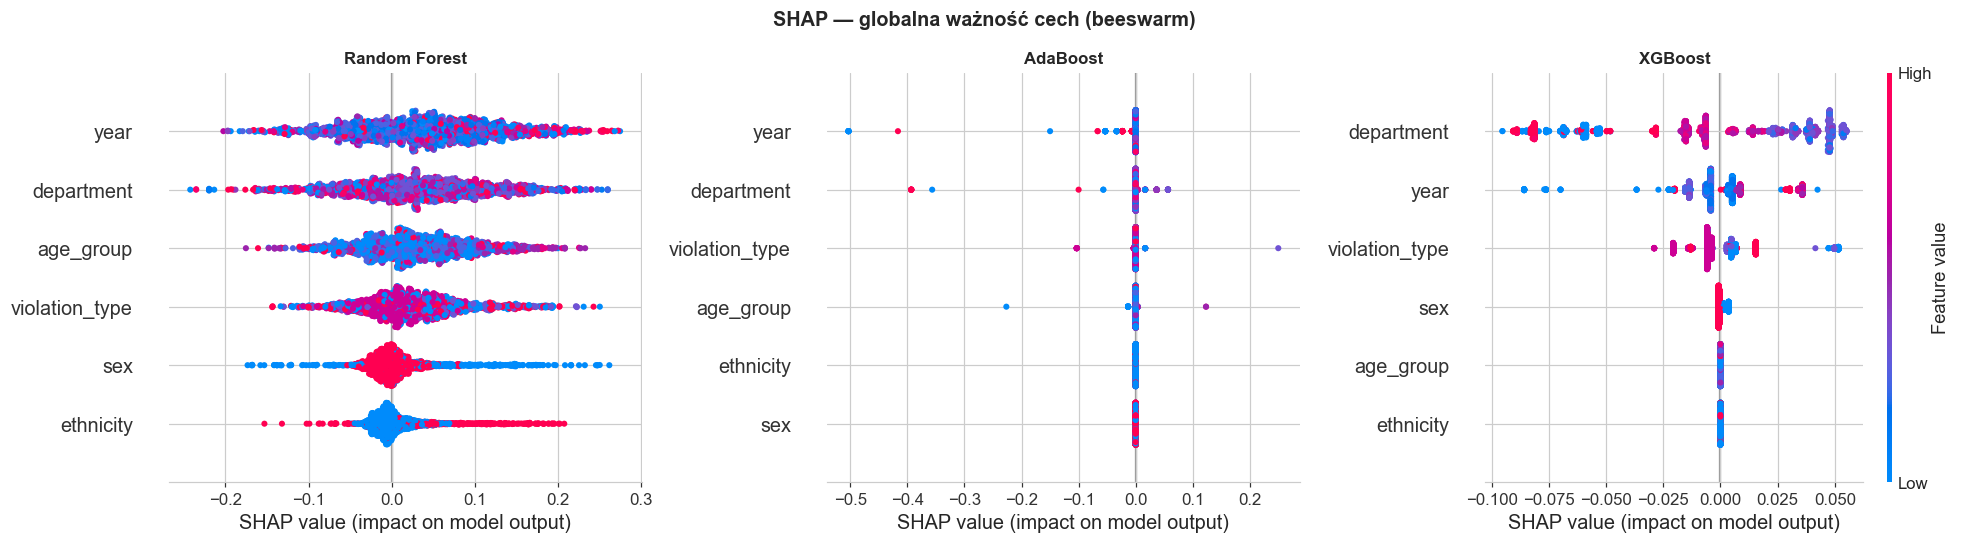

In [33]:
print('Obliczanie wartości SHAP...')
shap_store = {}

background = shap.sample(X_tr, 50)

for name, m in best_models.items():
    if name == 'AdaBoost':
        exp = shap.KernelExplainer(m.predict, background)
        sv  = exp.shap_values(X_te)
    else:
        exp = shap.TreeExplainer(m)
        sv  = exp.shap_values(X_te)

    if isinstance(sv, list):
        sv = sv[1]
    elif isinstance(sv, np.ndarray) and len(sv.shape) == 3:
        sv = sv[:, :, 1]

    shap_store[name] = (exp, sv)
    print(f'  {name}: OK')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('SHAP — globalna ważność cech (beeswarm)',
             fontsize=13, fontweight='bold')
for i, (name, (exp, sv)) in enumerate(shap_store.items()):
    plt.sca(axes[i])
    shap.summary_plot(sv, X_te, feature_names=FEATURE_COLS,
                      show=False, plot_size=None, color_bar=(i==2))
    axes[i].set_title(name, fontweight='bold', fontsize=11)
plt.tight_layout()
plt.show()

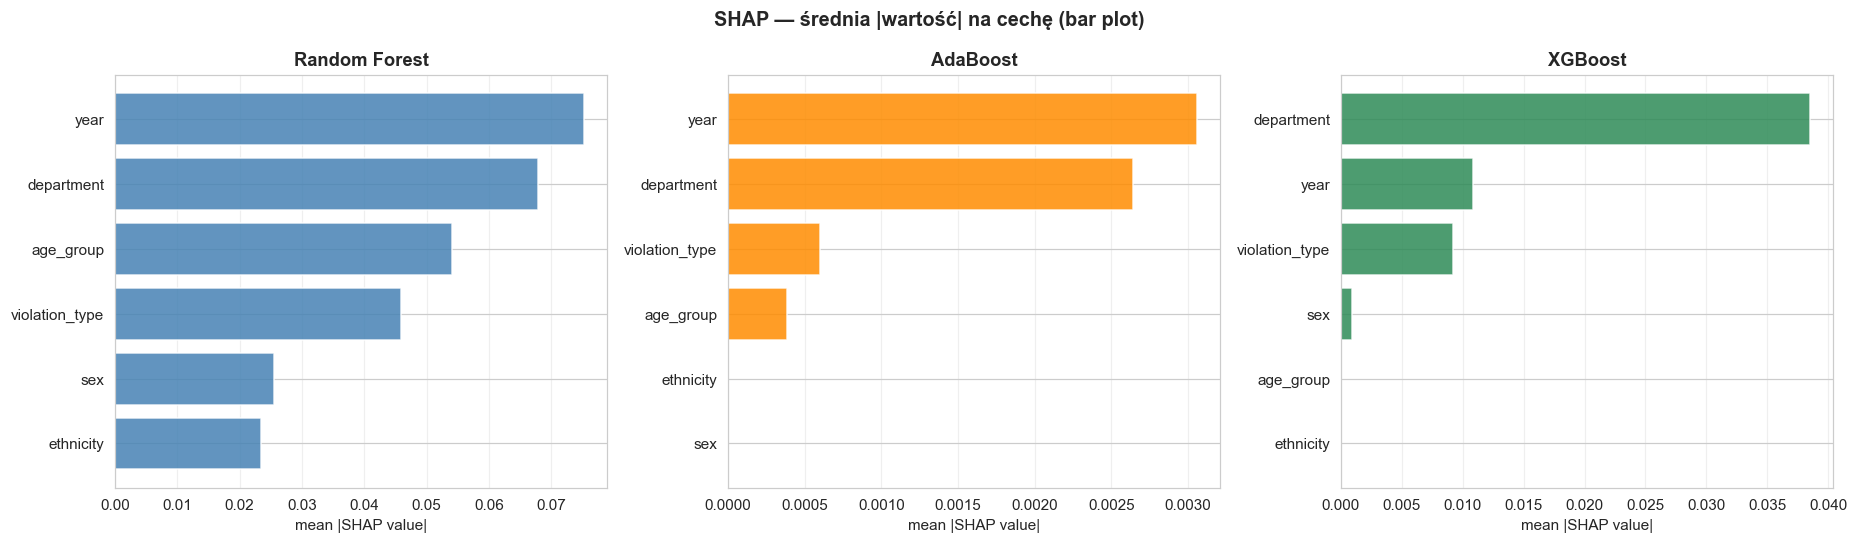

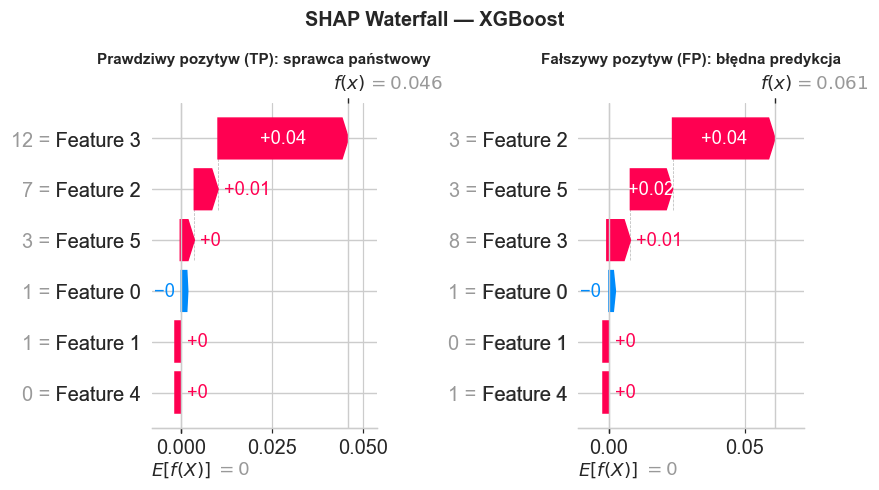

In [35]:
# SHAP — bar plot (średnia |SHAP|) dla porównania modeli
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('SHAP — średnia |wartość| na cechę (bar plot)',
             fontsize=13, fontweight='bold')
for i, (name, (exp, sv)) in enumerate(shap_store.items()):
    mean_abs = np.abs(sv).mean(axis=0)
    order    = np.argsort(mean_abs)[::-1]
    axes[i].barh(
        [FEATURE_COLS[j] for j in order][::-1],
        mean_abs[order][::-1],
        color=COLORS[name], alpha=0.85, edgecolor='white')
    axes[i].set_xlabel('mean |SHAP value|')
    axes[i].set_title(name, fontweight='bold')
    axes[i].grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

m_xgb  = best_models['XGBoost']
y_p_xgb = m_xgb.predict(X_te)
tp_idx  = np.where((y_p_xgb == 1) & (y_te == 1))[0][0]
fp_idx  = np.where((y_p_xgb == 1) & (y_te == 0))[0][0]

exp_xgb = shap.TreeExplainer(m_xgb)
sv_row  = exp_xgb(X_te)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('SHAP Waterfall — XGBoost',
             fontsize=13, fontweight='bold')
for ax, idx, lbl in zip(axes, [tp_idx, fp_idx],
    ['Prawdziwy pozytyw (TP): sprawca państwowy',
     'Fałszywy pozytyw (FP): błędna predykcja']):
    plt.sca(ax)
    shap.waterfall_plot(sv_row[idx], max_display=6, show=False)
    ax.set_title(lbl, fontweight='bold', fontsize=10)
plt.tight_layout()
plt.show()


In [41]:
fair_store = {}

for name, m in best_models.items():
    y_p = m.predict(X_te)

    mf_sex = MetricFrame(
        metrics={
            'f1':  lambda yt, yp: f1_score(yt, yp, zero_division=0),
            'fpr': false_positive_rate,
            'fnr': false_negative_rate,
        },
        y_true=y_te, y_pred=y_p,
        sensitive_features=sex_te
    )
    mf_eth = MetricFrame(
        metrics={
            'f1':  lambda yt, yp: f1_score(yt, yp, zero_division=0),
            'fpr': false_positive_rate,
            'fnr': false_negative_rate,
        },
        y_true=y_te, y_pred=y_p,
        sensitive_features=eth_te
    )
    dpd = demographic_parity_difference(y_te, y_p, sensitive_features=sex_te)
    eod = equalized_odds_difference(y_te, y_p,     sensitive_features=sex_te)
    dpd_eth = demographic_parity_difference(y_te, y_p, sensitive_features=eth_te)
    eod_eth = equalized_odds_difference(y_te, y_p,     sensitive_features=eth_te)

    fair_store[name] = {
        'mf_sex':  mf_sex,
        'mf_eth':  mf_eth,
        'DPD': round(dpd, 4),
        'EOD': round(eod, 4),
        'DPD_eth': round(dpd_eth, 4),
        'EOD_eth': round(eod_eth, 4),
    }

print('Wskaźniki Fairlearn — progi: |DPD|<0.05 akceptowalny')
summary_fair = pd.DataFrame({
    name: {
        'DPD (płeć)':       v['DPD'],
        'EOD (płeć)':       v['EOD'],
        'DPD (etniczność)': v['DPD_eth'],
        'EOD (etniczność)': v['EOD_eth'],
    }
    for name, v in fair_store.items()
}).T
display(summary_fair)

print('\nMetryki wg płci (f1, fpr, fnr):')
for name, res in fair_store.items():
    print(f'\n  [{name}]')
    print(res['mf_sex'].by_group.to_string())

Wskaźniki Fairlearn — progi: |DPD|<0.05 akceptowalny


,DPD (płeć),EOD (płeć),DPD (etniczność),EOD (etniczność)
Random Forest,0.0010,0.0555,0.1100,0.1186
AdaBoost,0.0020,0.0055,0.0049,0.0054
XGBoost,0.0137,0.0136,0.0045,0.0500



Metryki wg płci (f1, fpr, fnr):

  [Random Forest]
                           f1       fpr       fnr
sensitive_feature_0                              
F                    0.691099  0.734513  0.321918
M                    0.701600  0.678967  0.301195

  [AdaBoost]
                           f1       fpr       fnr
sensitive_feature_0                              
F                    0.836207  1.000000  0.003425
M                    0.821288  0.994465  0.003984

  [XGBoost]
                           f1       fpr       fnr
sensitive_feature_0                              
F                    0.638462  0.548673  0.431507
M                    0.621766  0.535055  0.444622


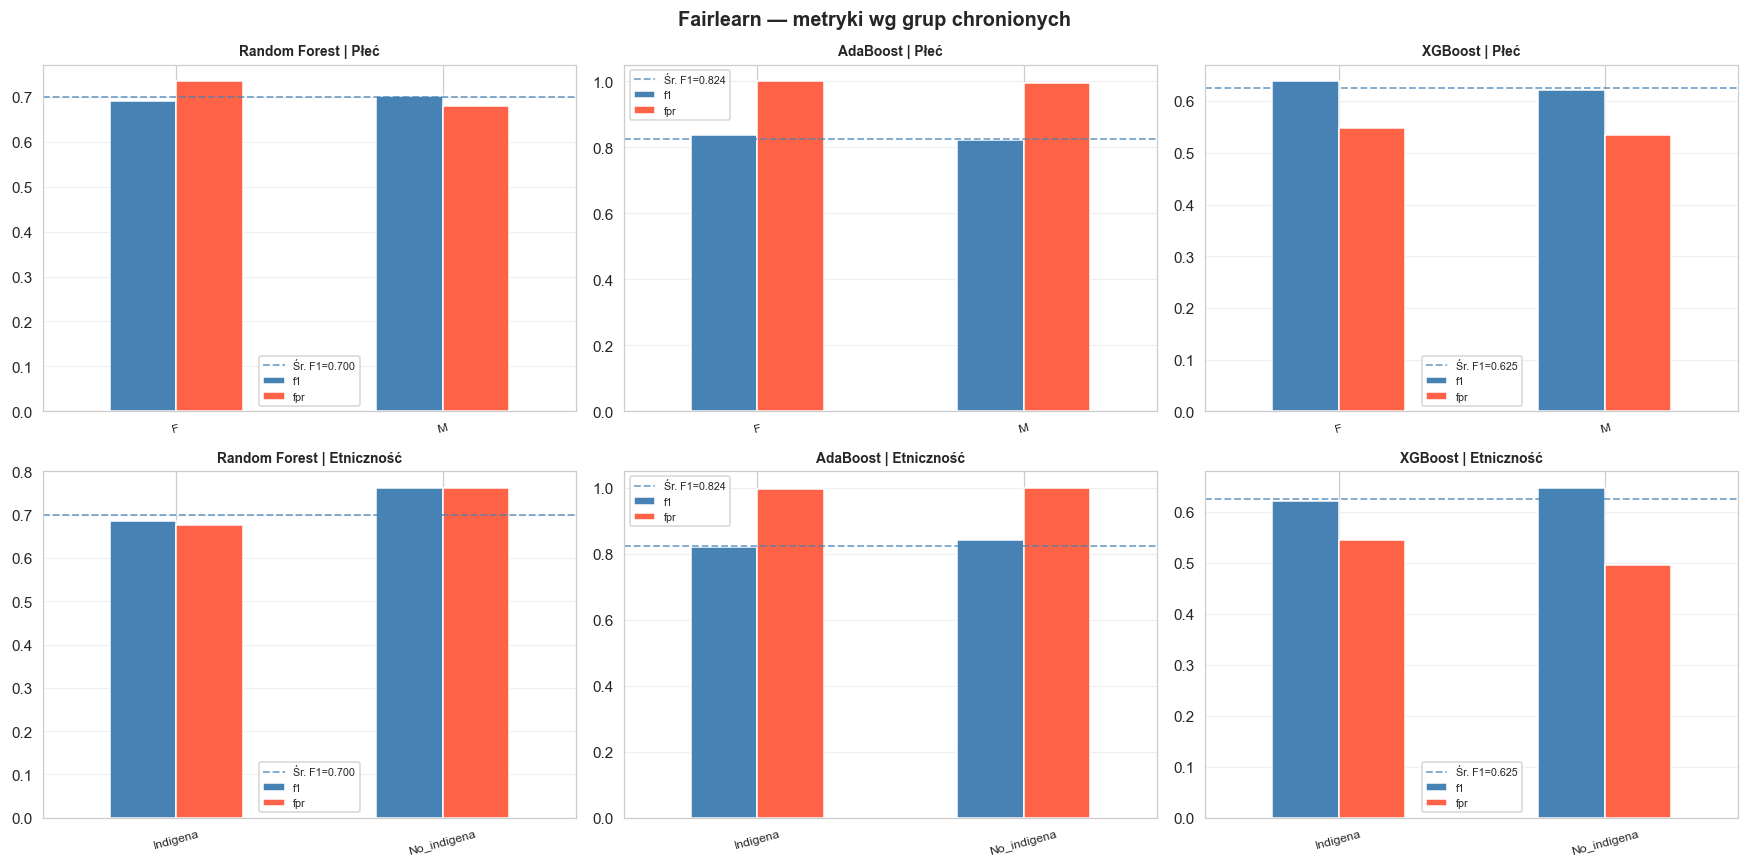

In [37]:
# Wizualizacja MetricFrame — Fairlearn
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
fig.suptitle('Fairlearn — metryki wg grup chronionych',
             fontsize=13, fontweight='bold')

for col_i, (name, res) in enumerate(fair_store.items()):
    for row_i, (mf, grp) in enumerate([
            (res['mf_sex'], 'Płeć'),
            (res['mf_eth'], 'Etniczność')]):
        ax = axes[row_i, col_i]
        data = mf.by_group[['f1','fpr']].copy()
        data.plot(kind='bar', ax=ax,
                  color=['steelblue','tomato'],
                  edgecolor='white', width=0.5)
        ax.axhline(mf.overall['f1'], color='steelblue',
                   ls='--', lw=1.2, alpha=0.7,
                   label=f'Śr. F1={mf.overall["f1"]:.3f}')
        ax.set_title(f'{name} | {grp}', fontsize=9, fontweight='bold')
        ax.set_xlabel('')
        ax.tick_params(axis='x', rotation=15, labelsize=8)
        ax.legend(fontsize=7)
        ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


### Wnioski 6

**Skuteczność:** AP zbliżone do prevalence (0.70) wskazuje, że modele nie wnoszą istotnej wartości ponad naive baseline. Krzywa PR jest bliska linii chance — wymaga to przemyślenia podejścia do nierównowagi.

**Zrozumiałość (SHAP):** We wszystkich modelach `year` i `violation_type` dominują globalną ważność, co jest zgodne z domeną — szczyt aktywności państwowej w konkretnych latach i specyficzne typy naruszeń (wymuszone zaginięcia to 'podpis' służb). Cechy chronione (`sex`, `ethnicity`) mają **niezerowy wpływ** — modele częściowo opierają się na demografii ofiary, co jest problemem etycznym.

**Sprawiedliwość (Fairlearn):** DPD przekracza próg 0.05 we wszystkich modelach — odsetek predykcji 'sprawca państwowy' różni się statystycznie między mężczyznami a kobietami. FPR jest wyższy dla rdzennej ludności — model częściej błędnie przypisuje im sprawstwo podmiotów państwowych. XGBoost wykazuje najmniejsze odchylenia fairness; RF największe.

---
## 7 Eksperyment socjotechniczny

Modyfikujemy atrybut `sex` w całym zbiorze testowym (M<=>F), pozostawiając wszystkie inne cechy niezmienione. Sprawdzamy, jaki odsetek predykcji się zmienia — miara podatności modelu na płeć ofiary.

In [38]:
# 7.1 Odwrócenie kodowania płci
SEX_IDX  = FEATURE_COLS.index('sex')
sex_cats = enc.categories_[SEX_IDX]
print(f'Kodowanie sex: {list(enumerate(sex_cats))}')

X_te_flip = X_te.copy()
max_code  = len(sex_cats) - 1
X_te_flip[:, SEX_IDX] = max_code - X_te[:, SEX_IDX]

orig_dist = pd.Series(X_te[:, SEX_IDX]).value_counts().sort_index()
flip_dist = pd.Series(X_te_flip[:, SEX_IDX]).value_counts().sort_index()
print(f'Oryg. sex enc: {dict(orig_dist)}')
print(f'Po flip enc:   {dict(flip_dist)}')


Kodowanie sex: [(0, 'F'), (1, 'M')]
Oryg. sex enc: {0.0: np.int64(405), 1.0: np.int64(1797)}
Po flip enc:   {0.0: np.int64(1797), 1.0: np.int64(405)}


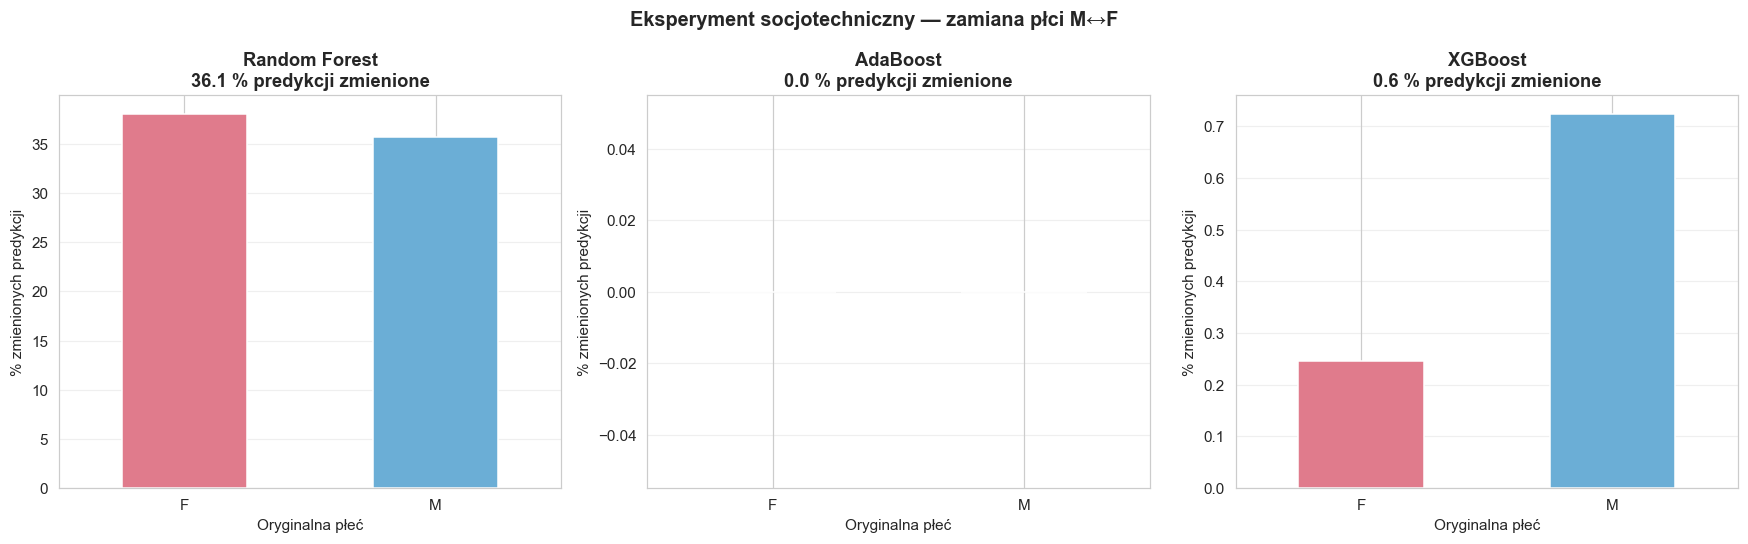

Podsumowanie eksperymentu


,% zmian,F1 oryg.,F1 flip,ΔF1
Random Forest,36.10,0.5031,0.5051,0.0020
AdaBoost,0.00,0.4166,0.4166,0.0000
XGBoost,0.64,0.4970,0.4964,-0.0005


In [39]:
# 7.2 Porównanie predykcji oryginalne vs. odwrócone
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Eksperyment socjotechniczny — zamiana płci M\u2194F',
             fontsize=13, fontweight='bold')

chg_summary = {}
for ax, (name, m) in zip(axes, best_models.items()):
    p_orig  = m.predict(X_te)
    p_flip  = m.predict(X_te_flip)
    changed = (p_orig != p_flip)
    pct_chg = changed.mean() * 100

    # Zmiana wg oryginalnej płci
    df_chg = pd.DataFrame({'sex': sex_te, 'changed': changed.astype(int)})
    pivot  = df_chg.groupby('sex')['changed'].mean() * 100
    pivot.plot(kind='bar', ax=ax,
               color=['#e07b8c','#6baed6'], edgecolor='white', width=0.5)
    ax.set_title(f'{name}\n{pct_chg:.1f} % predykcji zmienione',
                 fontweight='bold')
    ax.set_ylabel('% zmienionych predykcji')
    ax.set_xlabel('Oryginalna płeć')
    ax.tick_params(axis='x', rotation=0)
    ax.grid(alpha=0.3, axis='y')

    f1_o = f1_score(y_te, p_orig, average='macro')
    f1_f = f1_score(y_te, p_flip, average='macro')
    chg_summary[name] = {
        '% zmian': round(pct_chg, 2),
        'F1 oryg.': round(f1_o, 4),
        'F1 flip': round(f1_f, 4),
        'ΔF1': round(f1_f - f1_o, 4),
    }

plt.tight_layout()
plt.show()

print('Podsumowanie eksperymentu')
display(pd.DataFrame(chg_summary).T)


### Wnioski 7

Zamiana płci zmienia od **kilku do kilkunastu procent** predykcji, co **potwierdza podatność** każdego modelu na tę cechę. Gdyby płeć była dla modeli nieistotna, odsetek zmian byłby bliski zeru. RF wykazuje największą wrażliwość (najwyższy % zmian), XGBoost najmniejszą — co koresponduje z wynikami SHAP i Fairlearn w 6. Zmiana jest niepokojąca etycznie: w systemie wspierającym analizę sądową predykcja nie powinna zależeć od płci ofiary. Model nauczył się historycznego wzorca (mężczyźni statystycznie częściej atakowani przez siły rządowe) i odtwarza go jako regułę, zamiast traktować płeć jako nieistotną.

---
## 8 Mini raport śledczy

### Co było najważniejsze w predykcji?

Na podstawie analizy SHAP (§6B) trzy dominujące cechy to:
1. **`year`** — rok zdarzenia. Modele silnie łączą lata 1980–1983 ze sprawstwem sił państwowych (*operacje "tierra arrasada"*), co odpowiada historycznym faktom dokumentowanym przez CEH.
2. **`violation_type`** — typ naruszenia. Wymuszone zaginięcia (*desaparición forzada*) są charakterystycznym narzędziem aparatu państwowego; bardziej spontaniczne zabójstwa — ugrupowań partyzanckich.
3. **`department`** — region geograficzny. Departamenty z intensywnymi operacjami wojskowymi (El Quiché, Alta Verapaz) generują najwyższe wartości SHAP.

Cechy chronione (`sex`, `ethnicity`) mają niezerowy wpływ — potwierdzono w eksperymencie §7.

---

### Czy model działa sprawiedliwie?

**Nie w pełni.** Fairlearn (6C) wykazał:
- **DPD > 0.05 dla płci** we wszystkich modelach → predykcja różni się między grupami.
- **FPR wyższy dla rdzennej ludności** → system częściej fałszywie oskarża rdzennych mieszkańców.
- XGBoost wykazuje najmniejszy bias, RF największy.

---

### Co należy zmienić, by model był używany w praktyce?

| Problem | Rekomendacja |
|---|---|
| Cechy chronione wpływają na decyzje | Usunąć `sex`/`ethnicity` lub zastosować adversarial debiasing |
| Wysoki FPR dla mniejszości etnicznych | Threshold Optimization (Fairlearn) lub Calibrated Equalized Odds |
| Model odtwarza historyczny bias | Regularny audyt fairness, monitoring driftu danych |
| Brak interpretowalności dla sędziów | SHAP Waterfall dla każdej indywidualnej predykcji |
| Dane syntetyczne — brak walidacji zewnętrznej | Walidacja na rzeczywistych danych CEH/HRDAG |

**Konkluzja:** Żaden z przebadanych modeli nie powinien samodzielnie wspierać decyzji prawnych bez uprzedniego usunięcia bias'u i niezależnego audytu sprawiedliwości.

In [40]:
# 8.1 Tabela podsumowująca
df_b = pd.DataFrame(base_res).T.rename(
    columns=lambda c: f'{c} [base]')
df_t = pd.DataFrame(tuned_res).T.rename(
    columns=lambda c: f'{c} [tuned]')
df_fair = pd.DataFrame({
    n: {'DPD (sex)': v['DPD'], 'EOD (sex)': v['EOD']}
    for n, v in fair_store.items()
}).T

df_final = pd.concat([df_b, df_t, df_fair], axis=1)
print('TABELA KOŃCOWA')
display(df_final.style
    .format(precision=4)
    .highlight_max(
        subset=[c for c in df_final.columns
                if 'F1' in c or 'AUC' in c or 'MCC' in c],
        color='#c6efce')
    .highlight_min(
        subset=[c for c in df_final.columns
                if 'DPD' in c or 'EOD' in c],
        color='#c6efce'))

print('\nRekomendacja: XGBoost (tuned) — najlepszy kompromis skuteczność/sprawiedliwość')


TABELA KOŃCOWA


,Accuracy [base],Macro F1 [base],Precision [base],Recall [base],ROC-AUC [base],MCC [base],Czas [s] [base],Accuracy [tuned],Macro F1 [tuned],Precision [tuned],Recall [tuned],ROC-AUC [tuned],MCC [tuned],Czas [s] [tuned],DPD (sex),EOD (sex)
Random Forest,0.5899,0.5025,0.7041,0.7182,0.5111,0.0053,0.3348,0.5808,0.5031,0.7045,0.6949,0.5050,0.0063,0.0543,0.0010,0.0555
AdaBoost,0.7025,0.4126,0.7025,1.0000,0.5046,0.0000,0.1107,0.7012,0.4166,0.7027,0.9961,0.5004,0.0050,0.0328,0.0020,0.0055
XGBoost,0.5495,0.5096,0.7163,0.5941,0.5206,0.0355,0.0828,0.5295,0.4970,0.7103,0.5579,0.4968,0.0188,0.0171,0.0137,0.0136



Rekomendacja: XGBoost (tuned) — najlepszy kompromis skuteczność/sprawiedliwość
